# Projet final : les récoltes agricoles

**Équipe :** Ekip001,DALEUS Roodlyson, MICHEL Marx Darwin, OLESTIL Roubens.

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

brut = pd.read_csv("donnees/recoltes_brut.csv")
cultures = pd.read_csv("donnees/cultures.csv")
pluies = pd.read_csv("donnees/pluies.csv")
departements = pd.read_csv("donnees/departements.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [2]:
# Forme et types : surface_ha et production_t devraient être des nombres
display(brut.shape)
display(brut.dtypes)

# Valeurs manquantes et lignes en double
display(brut.isna().sum())
display(f"{brut.duplicated().sum()} lignes en double (copies exactes d'une autre ligne)")

# Toutes les écritures d'une même valeur dans les colonnes de texte
for col in ["saison", "departement", "culture"]:
    display(f"{col} : {brut[col].nunique()} écritures différentes", sorted(brut[col].unique()))

# Nombres écrits comme du texte : on cherche ce qui n'est pas une suite de chiffres
surface_texte = brut[~brut["surface_ha"].str.fullmatch(r"\d+")]
production_texte = brut[brut["production_t"].notna() & ~brut["production_t"].str.fullmatch(r"\d+", na=False)]
display(surface_texte["surface_ha"].head(6).tolist(), production_texte["production_t"].head(6).tolist())

# Problèmes trouvés, à corriger à l'étape 2
pd.DataFrame(
    [
        ("Casse et espaces parasites dans departement", f"{brut['departement'].nunique()} écritures pour {departements['departement'].nunique()} départements"),
        ("Casse et espaces parasites dans culture", f"{brut['culture'].nunique()} écritures pour {cultures['culture'].nunique()} cultures"),
        ("Surfaces écrites en texte (unité « ha » ou espace des milliers)", f"{len(surface_texte)} lignes"),
        ("Productions écrites en texte (unité « t »)", f"{len(production_texte)} lignes"),
        ("Productions manquantes", f"{brut['production_t'].isna().sum()} lignes"),
        ("Lignes en double", f"{brut.duplicated().sum()} lignes"),
    ],
    columns=["problème", "constat"],
)

(408, 6)

annee           int64
saison            str
departement       str
culture           str
surface_ha        str
production_t      str
dtype: object

annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64

"18 lignes en double (copies exactes d'une autre ligne)"

'saison : 2 écritures différentes'

['Automne', 'Printemps']

... (3 outputs left out)

[' Banane',
 ' Haricot',
 ' Igname',
 ' Maïs',
 ' Pois congo',
 ' Riz',
 ' Sorgho',
 'BANANE',
 'Banane',
 'Banane ',
 'HARICOT',
 'Haricot',
 'Haricot ',
 'IGNAME',
 'Igname',
 'Igname ',
 'MAÏS',
 'Maïs',
 'Maïs ',
 'POIS CONGO',
 'Pois congo',
 'Pois congo ',
 'Riz',
 'Riz ',
 'SORGHO',
 'Sorgho',
 'Sorgho ',
 'banane',
 'haricot',
 'igname',
 'maïs',
 'pois congo',
 'sorgho']

['2 517', '541 ha', '1 127', '1 185', '1 185', '1 748']

['3753 t', '2299 t', '1306 t', '2394 t', '599 t', '767 t']

,problème,constat
0,Casse et espaces parasites dans departement,44 écritures pour 10 départements
1,Casse et espaces parasites dans culture,33 écritures pour 7 cultures
2,Surfaces écrites en texte (unité « ha » ou esp...,22 lignes
3,Productions écrites en texte (unité « t »),50 lignes
4,Productions manquantes,15 lignes
5,Lignes en double,18 lignes


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [3]:
# Une copie : brut reste intact pour pouvoir comparer
propre = brut.copy()

# --- Problème 1 : casse et espaces parasites (saison, departement, culture) ---
# On enlève les espaces et on passe en minuscules, puis on remet les noms officiels
# de departements.csv et cultures.csv. Aucune ligne n'est supprimée : on regroupe les écritures.
for col in ["saison", "departement", "culture"]:
    propre[col] = propre[col].str.strip().str.lower()
propre["departement"] = propre["departement"].map({d.lower(): d for d in departements["departement"]})
propre["culture"] = propre["culture"].map({c.lower(): c for c in cultures["culture"]})
propre["saison"] = propre["saison"].str.capitalize()
assert propre[["saison", "departement", "culture"]].notna().all().all()  # aucun nom inconnu
display({col: propre[col].nunique() for col in ["saison", "departement", "culture"]})

# --- Problème 2 : nombres écrits en texte ---
# On garde uniquement les chiffres (\D = tout sauf un chiffre : retire " ha", " t", espaces des milliers).
# Une chaîne vide devient une valeur manquante, traitée au problème 4.
for col in ["surface_ha", "production_t"]:
    chiffres = propre[col].astype("string").str.replace(r"\D", "", regex=True)
    propre[col] = pd.to_numeric(chiffres.replace("", pd.NA))
display(propre[["surface_ha", "production_t"]].dtypes)

# --- Problème 3 : lignes en double ---
# Fait APRÈS la normalisation : " Ouest" et "Ouest" étaient deux valeurs différentes avant.
# On supprime les copies exactes : sinon la même récolte serait comptée deux fois dans les totaux.
avant = len(propre)
propre = propre.drop_duplicates()
display(f"Doublons : {avant} → {len(propre)} lignes ({avant - len(propre)} copies exactes supprimées, la même récolte était comptée deux fois)")

# --- Problème 4 : productions manquantes ---
# On supprime ces lignes : sans production, on ne peut calculer ni rendement ni valeur,
# et inventer un chiffre fausserait les totaux.
avant = len(propre)
propre = propre.dropna().reset_index(drop=True)
propre["surface_ha"] = propre["surface_ha"].astype(int)
propre["production_t"] = propre["production_t"].astype(int)
display(f"Productions manquantes : {avant} → {len(propre)} lignes ({avant - len(propre)} lignes sans production supprimées)")

# --- Contrôle final ---
controle = {
    "forme": propre.shape,
    "valeurs manquantes": int(propre.isna().sum().sum()),
    "doublons": int(propre.duplicated().sum()),
    "saison": propre["saison"].nunique(),
    "departement": propre["departement"].nunique(),
    "culture": propre["culture"].nunique(),
}
assert controle["forme"] == (376, 6)
controle

{'saison': 2, 'departement': 10, 'culture': 7}

surface_ha      Int64
production_t    Int64
dtype: object

'Doublons : 408 → 390 lignes (18 copies exactes supprimées, la même récolte était comptée deux fois)'

'Productions manquantes : 390 → 376 lignes (14 lignes sans production supprimées)'

{'forme': (376, 6),
 'valeurs manquantes': 0,
 'doublons': 0,
 'saison': 2,
 'departement': 10,
 'culture': 7}

## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [4]:
# validate="many_to_one" fait planter le code si la clé n'est pas unique à droite :
# on ne peut pas multiplier les lignes sans s'en rendre compte.

# cultures.csv (une ligne par culture) : famille, rendement moyen, prix
avant = len(propre)
complet = propre.merge(cultures, on="culture", how="left", validate="many_to_one")
display(f"Jointure cultures.csv : {avant} → {len(complet)} lignes")

# pluies.csv (une ligne par année, saison et département)
avant = len(complet)
complet = complet.merge(pluies, on=["annee", "saison", "departement"], how="left", validate="many_to_one")
display(f"Jointure pluies.csv : {avant} → {len(complet)} lignes")

# departements.csv (une ligne par département) : population et superficie, pour la question 5 et le tableau de bord
avant = len(complet)
complet = complet.merge(departements, on="departement", how="left", validate="many_to_one")
display(f"Jointure departements.csv : {avant} → {len(complet)} lignes")

# Colonnes calculées
complet["rendement_t_ha"] = complet["production_t"] / complet["surface_ha"]    # tonnes par hectare
complet["valeur_htg"] = complet["production_t"] * 1000 * complet["prix_htg_kg"]  # tonnes → kg, puis prix au kg

# Contrôle : 376 lignes, et aucune jointure n'a laissé de case vide
assert len(complet) == 376
display({"lignes": len(complet), "cases vides": int(complet.isna().sum().sum())})
complet.head()

'Jointure cultures.csv : 376 → 376 lignes'

'Jointure pluies.csv : 376 → 376 lignes'

'Jointure departements.csv : 376 → 376 lignes'

{'lignes': 376, 'cases vides': 0}

,annee,saison,departement,culture,surface_ha,production_t,famille,rendement_moyen_t_ha,prix_htg_kg,pluie_mm,chef_lieu,population,superficie_km2,rendement_t_ha,valeur_htg
0,2023,Printemps,Ouest,Maïs,1488,1327,céréale,1.1,22.0,369,Port-au-Prince,4029705,4983,0.891801,29194000.0
1,2023,Printemps,Ouest,Sorgho,3577,2629,céréale,0.9,20.0,369,Port-au-Prince,4029705,4983,0.734973,52580000.0
2,2023,Printemps,Ouest,Riz,2453,6122,céréale,2.6,38.0,369,Port-au-Prince,4029705,4983,2.495720,232636000.0
3,2023,Printemps,Ouest,Haricot,814,464,légumineuse,0.7,65.0,369,Port-au-Prince,4029705,4983,0.570025,30160000.0
4,2023,Printemps,Ouest,Pois congo,2436,1710,légumineuse,0.8,55.0,369,Port-au-Prince,4029705,4983,0.701970,94050000.0


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [5]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)

complet.shape

(376, 15)

## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

,production_t,valeur_htg,part_tonnes,part_valeur,rang_tonnes,rang_valeur
culture,,,,,,
Banane,547615,6.571380e+09,41.4,20.2,1,2
Igname,402302,1.206906e+10,30.4,37.1,2,1
Riz,136225,5.176550e+09,10.3,15.9,3,3
Maïs,75311,1.656842e+09,5.7,5.1,4,6
Sorgho,61354,1.227080e+09,4.6,3.8,5,7
Pois congo,56626,3.114430e+09,4.3,9.6,6,4
Haricot,42323,2.750995e+09,3.2,8.4,7,5


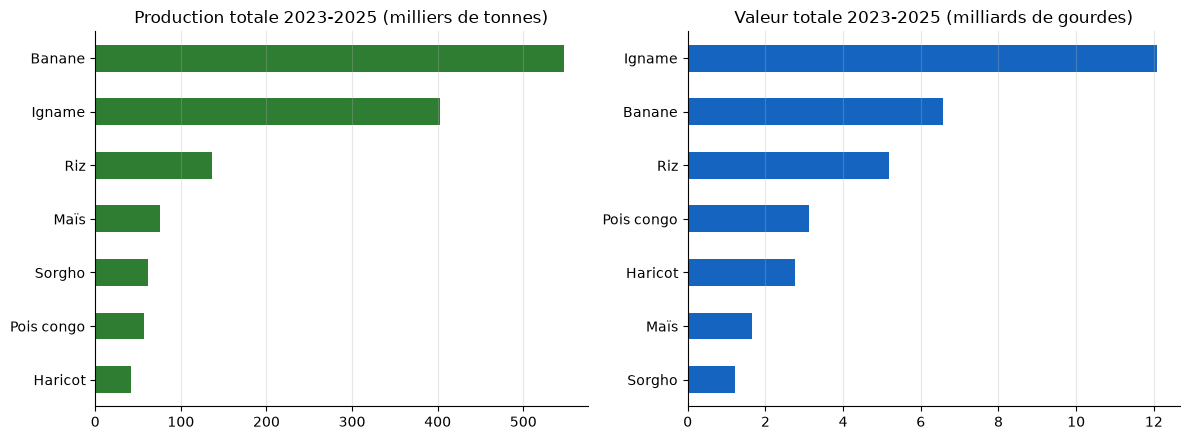

In [6]:
classement = (
    complet.groupby("culture")[["production_t", "valeur_htg"]].sum()
    .assign(
        part_tonnes=lambda d: d["production_t"] / d["production_t"].sum() * 100,
        part_valeur=lambda d: d["valeur_htg"] / d["valeur_htg"].sum() * 100,
        rang_tonnes=lambda d: d["production_t"].rank(ascending=False).astype(int),
        rang_valeur=lambda d: d["valeur_htg"].rank(ascending=False).astype(int),
    )
    .sort_values("production_t", ascending=False)
)
display(classement.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
(classement["production_t"].sort_values() / 1000).plot.barh(ax=axes[0], color="#2E7D32")
axes[0].set_title("Production totale 2023-2025 (milliers de tonnes)")
(classement["valeur_htg"].sort_values() / 1e9).plot.barh(ax=axes[1], color="#1565C0")
axes[1].set_title("Valeur totale 2023-2025 (milliards de gourdes)")
for ax in axes:
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** le classement change. En tonnes, la **banane** domine (547 615 t, 41,4 % du total) devant l'**igname** (402 302 t, 30,4 %) ; en valeur, l'igname passe première (12,1 milliards de gourdes, 37,1 %) et la banane deuxième (6,6 milliards, 20,2 %), parce que l'igname se vend 30 gourdes le kg contre 12 pour la banane. Le **haricot** et le **pois congo** gagnent deux places (7e → 5e et 6e → 4e) grâce à des prix élevés (65 et 55 gourdes le kg), alors que le **maïs** et le **sorgho** reculent (4e → 6e et 5e → 7e). Le riz reste 3e dans les deux classements.

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

culture,Banane,Haricot,Igname,Maïs,Pois congo,Riz,Sorgho
departement,,,,,,,
Artibonite,7.10,0.64,5.79,0.96,0.77,3.80,0.79
Centre,6.64,0.78,5.53,1.20,0.82,NaN,1.08
Grand'Anse,8.66,0.69,8.24,1.11,0.73,NaN,0.91
Nippes,7.21,0.71,5.30,1.05,0.76,NaN,0.85
Nord,9.05,0.70,5.74,1.08,0.74,2.43,0.90
Nord-Est,6.23,0.61,5.32,0.91,0.63,2.12,0.77
Nord-Ouest,6.55,0.60,5.44,0.99,1.01,NaN,0.82
Ouest,6.89,0.63,5.74,1.06,0.80,2.38,0.83
Sud,8.01,0.88,6.56,1.15,0.80,2.68,0.80


,meilleur département,rendement max (t/ha),pire département,rendement min (t/ha)
culture,,,,
Banane,Nord,9.05,Nord-Est,6.23
Haricot,Sud,0.88,Nord-Ouest,0.60
Igname,Grand'Anse,8.24,Nippes,5.30
Maïs,Centre,1.20,Nord-Est,0.91
Pois congo,Nord-Ouest,1.01,Nord-Est,0.63
Riz,Artibonite,3.80,Nord-Est,2.12
Sorgho,Centre,1.08,Nord-Est,0.77


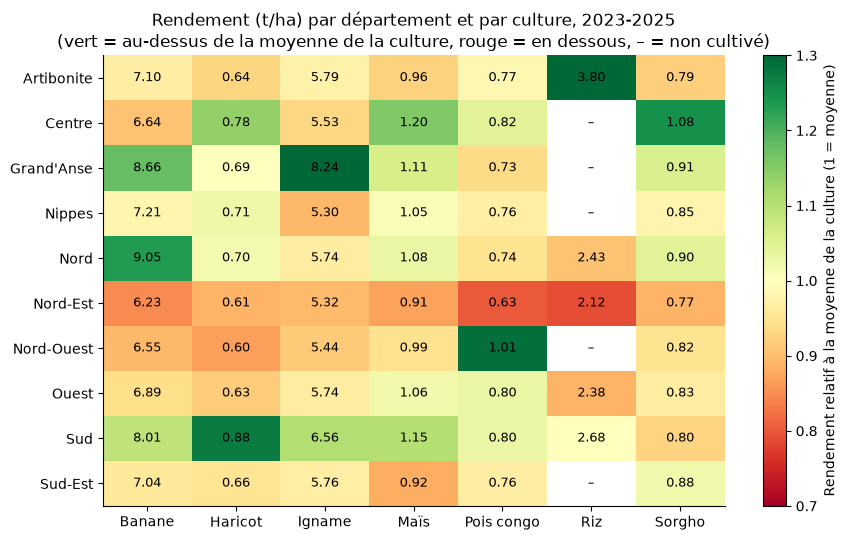

In [7]:
rendements = (
    complet.groupby(["culture", "departement"])[["production_t", "surface_ha"]].sum()
    .assign(rendement=lambda d: d["production_t"] / d["surface_ha"])["rendement"]
    .unstack("culture")
)
display(rendements.round(2))

meilleurs = pd.DataFrame({
    "meilleur département": rendements.idxmax(),
    "rendement max (t/ha)": rendements.max().round(2),
    "pire département": rendements.idxmin(),
    "rendement min (t/ha)": rendements.min().round(2),
})
display(meilleurs)

# Les cultures n'ont pas la même échelle (banane ≈ 7 t/ha, haricot ≈ 0,7) :
# on colore chaque case selon l'écart à la moyenne de SA culture, et on écrit la vraie valeur.
indice = rendements / rendements.mean()

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(indice.values, cmap="RdYlGn", vmin=0.7, vmax=1.3, aspect="auto")
ax.set_xticks(range(len(rendements.columns)), rendements.columns)
ax.set_yticks(range(len(rendements.index)), rendements.index)
for i in range(rendements.shape[0]):
    for j in range(rendements.shape[1]):
        valeur = rendements.iat[i, j]
        ax.text(j, i, "–" if pd.isna(valeur) else f"{valeur:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Rendement (t/ha) par département et par culture, 2023-2025\n(vert = au-dessus de la moyenne de la culture, rouge = en dessous, – = non cultivé)")
fig.colorbar(im, ax=ax, label="Rendement relatif à la moyenne de la culture (1 = moyenne)")
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** les meilleurs rendements dépendent de la culture : **banane** dans le Nord (9,05 t/ha), **igname** en Grand'Anse (8,24), **riz** en Artibonite (3,80), **maïs** et **sorgho** dans le Centre (1,20 et 1,08), **haricot** dans le Sud (0,88), **pois congo** dans le Nord-Ouest (1,01). Le **Sud** se place dans les deux premiers pour quatre cultures sur sept (igname, haricot, maïs, riz). À l'inverse, le **Nord-Est** a le plus faible rendement pour cinq cultures sur sept (banane, maïs, pois congo, riz, sorgho). Le riz n'est cultivé que dans 5 départements sur 10.

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

Haricot       0.76
Maïs          0.76
Igname        0.69
Sorgho        0.68
Banane        0.65
Pois congo    0.63
Riz           0.42
Name: corrélation rendement ~ pluie, dtype: float64

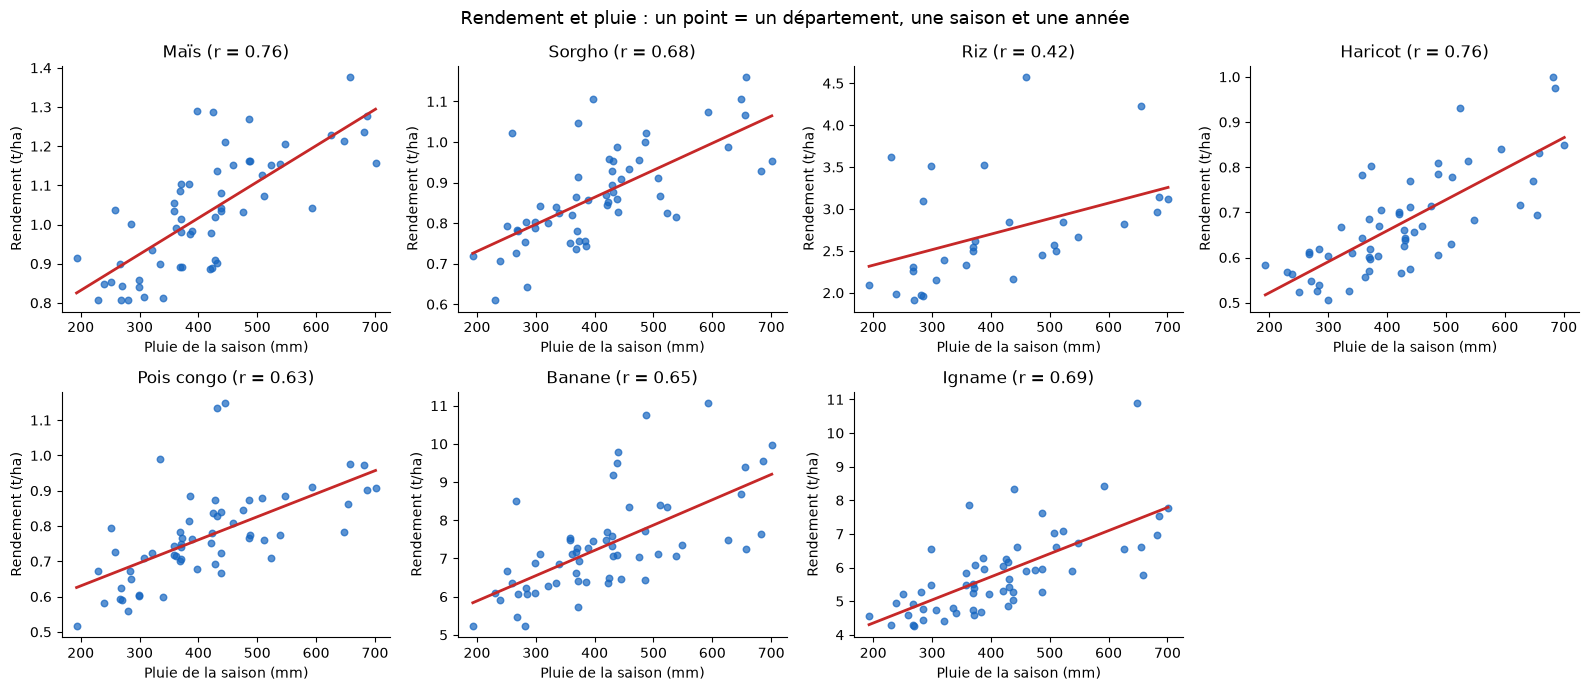

In [8]:
correlations = pd.Series({
    nom: complet.loc[complet["culture"] == nom, "rendement_t_ha"].corr(complet.loc[complet["culture"] == nom, "pluie_mm"])
    for nom in cultures["culture"]
}, name="corrélation rendement ~ pluie").sort_values(ascending=False)
display(correlations.round(2))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
for ax, nom in zip(axes, cultures["culture"]):
    d = complet[complet["culture"] == nom]
    ax.scatter(d["pluie_mm"], d["rendement_t_ha"], s=22, alpha=0.7, color="#1565C0")
    pente, ordonnee = np.polyfit(d["pluie_mm"], d["rendement_t_ha"], 1)
    x = np.array([d["pluie_mm"].min(), d["pluie_mm"].max()])
    ax.plot(x, pente * x + ordonnee, color="#C62828", linewidth=2)
    ax.set_title(f"{nom} (r = {correlations[nom]:.2f})")
    ax.set_xlabel("Pluie de la saison (mm)")
    ax.set_ylabel("Rendement (t/ha)")
axes[-1].set_visible(False)
fig.suptitle("Rendement et pluie : un point = un département, une saison et une année", fontsize=13)
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** la pluie et le rendement évoluent dans le même sens pour **les 7 cultures**, mais avec une force très inégale : r = 0,76 pour le **haricot** et le **maïs** (la pluie « explique » environ 58 % des écarts de rendement), 0,63 à 0,69 pour l'igname, le sorgho, la banane et le pois congo, et seulement 0,42 pour le **riz** (environ 18 %). La pluie compte donc beaucoup pour les cultures pluviales à petit rendement, mais jamais seule : il reste toujours une grande part inexpliquée (sol, semences, engrais, irrigation). Attention : une corrélation n'est pas une preuve de cause, et chaque nuage ne compte que 30 à 60 points (30 pour le riz).

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

,production 2023 (t),production 2025 (t),variation production (%),variation surface (%)
culture,,,,
Igname,161924,109809,-32.2,-31.5
Haricot,16081,14083,-12.4,-8.2
Maïs,27006,23972,-11.2,-16.8
Pois congo,17484,16871,-3.5,-5.1
Banane,182892,198322,8.4,2.6
Sorgho,20478,24091,17.6,17.5
Riz,44064,52501,19.1,4.1


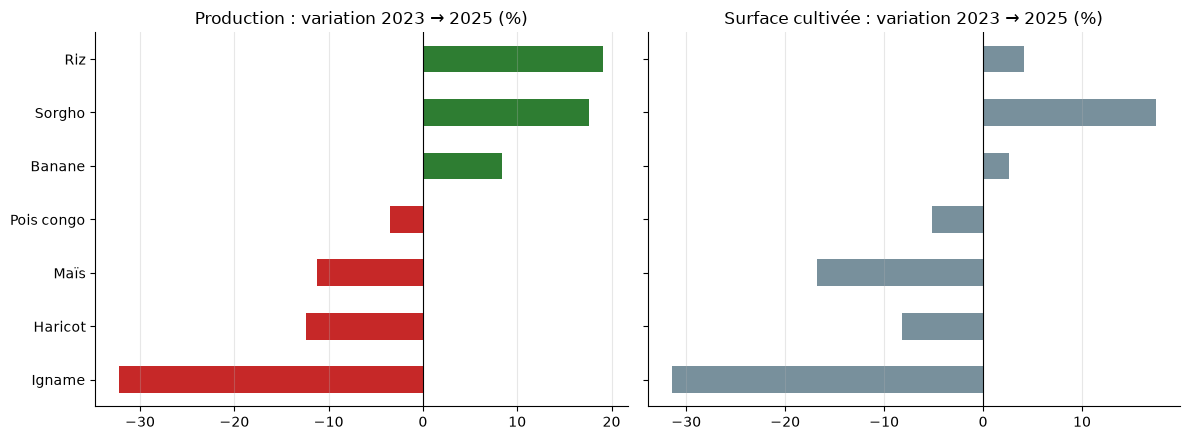

In [9]:
production = complet.pivot_table(index="culture", columns="annee", values="production_t", aggfunc="sum")
surface = complet.pivot_table(index="culture", columns="annee", values="surface_ha", aggfunc="sum")

evolution = pd.DataFrame({
    "production 2023 (t)": production[2023],
    "production 2025 (t)": production[2025],
    "variation production (%)": (production[2025] / production[2023] - 1) * 100,
    "variation surface (%)": (surface[2025] / surface[2023] - 1) * 100,
}).sort_values("variation production (%)")
display(evolution.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
couleurs = np.where(evolution["variation production (%)"] >= 0, "#2E7D32", "#C62828")
evolution["variation production (%)"].plot.barh(ax=axes[0], color=couleurs)
axes[0].set_title("Production : variation 2023 → 2025 (%)")
evolution["variation surface (%)"].plot.barh(ax=axes[1], color="#78909C")
axes[1].set_title("Surface cultivée : variation 2023 → 2025 (%)")
for ax in axes:
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** trois cultures progressent, le **riz** (+19,1 %), le **sorgho** (+17,6 %) et la **banane** (+8,4 %) ; quatre reculent, l'**igname** (−32,2 %), le **haricot** (−12,4 %), le **maïs** (−11,2 %) et le **pois congo** (−3,5 %). Le graphique de droite montre que ces écarts suivent surtout les **surfaces cultivées** : l'igname perd 31,5 % de surface alors que son rendement reste stable (5,9 t/ha en 2023 comme en 2025), et le sorgho gagne 17,5 % de surface. Seul le riz progresse nettement par le rendement (2,63 → 3,00 t/ha). Au total, la production passe de 469 929 t (2023) à 439 649 t (2025), soit −6,4 %, avec un creux en 2024 (412 178 t) qui correspond aussi à la plus petite surface cultivée (144 282 ha).

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

,production_t,population,kg_par_habitant_an,rang_tonnes
departement,,,,
Grand'Anse,114384,468301,81.4,6
Centre,167080,746236,74.6,3
Sud,155168,774976,66.7,4
Nord-Est,75030,393967,63.5,9
Artibonite,269226,1727524,51.9,1
Nippes,49223,342525,47.9,10
Sud-Est,80796,632601,42.6,8
Nord-Ouest,87192,728807,39.9,7
Nord,118791,1067177,37.1,5


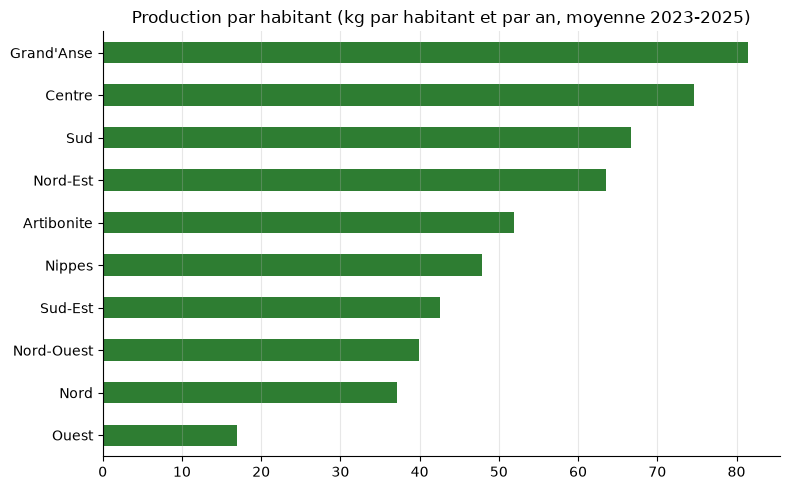

In [10]:
n_annees = complet["annee"].nunique()

par_habitant = (
    complet.groupby("departement")
    .agg(production_t=("production_t", "sum"), population=("population", "first"))
    .assign(kg_par_habitant_an=lambda d: d["production_t"] * 1000 / d["population"] / n_annees)
    .sort_values("kg_par_habitant_an", ascending=False)
)
par_habitant["rang_tonnes"] = par_habitant["production_t"].rank(ascending=False).astype(int)
display(par_habitant.round(1))

ax = par_habitant["kg_par_habitant_an"].sort_values().plot.barh(figsize=(8, 5), color="#2E7D32")
ax.set_title("Production par habitant (kg par habitant et par an, moyenne 2023-2025)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :** la **Grand'Anse** (81 kg par habitant et par an), le **Centre** (75) et le **Sud** (67) produisent le plus par habitant. L'**Ouest**, deuxième département en tonnes (204 866 t), est dernier avec 17 kg par habitant : il porte 4 millions d'habitants, autour de Port-au-Prince. L'**Artibonite**, premier en tonnes (269 226 t), n'est que 5e par habitant (52 kg). Le classement en tonnes et le classement par habitant ne disent donc pas la même chose. Limite : la population est une valeur unique (pas une série par année) et la production n'est pas la consommation, puisque les échanges entre départements ne sont pas mesurés.

## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.

1. L'**igname** et la **banane** pèsent 72 % des tonnes et 57 % de la valeur : la banane est première en tonnes (41 %), l'igname en valeur (37 %), et les deux légumineuses (haricot, pois congo), qui pèsent 7,5 % des tonnes, représentent 18 % de la valeur grâce à leur prix.
2. Les meilleurs rendements dépendent de la culture (Nord pour la banane, Grand'Anse pour l'igname, Sud et Centre pour plusieurs autres) et le Nord-Est est dernier pour cinq cultures sur sept.
3. La pluie va dans le même sens que le rendement pour les 7 cultures (r de 0,42 à 0,76) sans l'expliquer entièrement, et le recul de l'igname (−32 %) vient surtout de la baisse des surfaces cultivées, pas de la pluie.
4. Les données ne permettent pas de prouver une cause : seulement 3 ans et 2 saisons, des données fictives, un prix par culture constant sur toute la période, une population unique et du riz dans 5 départements seulement.
5. Il faudrait mesurer ensuite les températures, l'irrigation, les engrais, les prix réels de chaque année et la population année par année.